In [14]:
# Cell 1 — Load and Validate Cleaned Data
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

df = pd.read_csv("../data/processed/customer_support_tickets_clean.csv")

print(f"Duplicated tickets: {df.duplicated().sum()}")

invalid_type = df["Ticket Type"].fillna("").str.strip().eq("").sum()
print(f"Invalid or empty Ticket Type values: {invalid_type}")

invalid_description = (
    df["Ticket Description"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

print(f"Invalid or empty Ticket Description values: {invalid_description}")

Duplicated tickets: 0
Invalid or empty Ticket Type values: 0
Invalid or empty Ticket Description values: 0


In [15]:
# Cell 2 — Define X and Y
X = df["Ticket Description"]
y = df["Ticket Type"]

In [16]:
# Cell 3 — Create 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state= 42
)

In [17]:
# Cell 4 — Create Vectorizer
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [18]:
# Cell 5 — Create and train Logistic Regression Model
model = LogisticRegression()
model.fit(X_train_tfidf, y_train)

LogisticRegression()

In [19]:
# Cell 6 — Generate Test Predictions
y_pred = model.predict(X_test_tfidf)

### Correction Code
- The following cells will calculate what percentage of test tickets the models classified into the correct ticket type.

In [20]:
# Cell 7 — Calculate Overall Accuracy
model_accuracy = accuracy_score(y_test, y_pred)

print(f"Overall Accuracy: {model_accuracy:.2%}")

Overall Accuracy: 19.48%


In [21]:
# Cell 8 — Calculate Precision, Recall, and F1 Score
precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print(f"Weighted Precision: {precision:.2%}")
print(f"Weighted Recall: {recall:.2%}")
print(f"Weighted F1 Score: {f1:.2%}")

Weighted Precision: 19.45%
Weighted Recall: 19.48%
Weighted F1 Score: 19.45%


In [22]:
# Cell 9 — Generate Classification Report
report = classification_report(y_test, y_pred)
print(report)

                      precision    recall  f1-score   support

     Billing Inquiry       0.17      0.17      0.17       327
Cancellation Request       0.19      0.18      0.18       339
     Product Inquiry       0.21      0.22      0.21       328
      Refund Request       0.20      0.21      0.21       351
     Technical Issue       0.19      0.20      0.20       349

            accuracy                           0.19      1694
           macro avg       0.19      0.19      0.19      1694
        weighted avg       0.19      0.19      0.19      1694



In [23]:
# Cell 10 — Create Confusion Matrix
matrix = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

print(matrix)

[[54 59 73 73 68]
 [74 61 58 72 74]
 [57 59 71 65 76]
 [72 59 67 73 80]
 [52 84 65 77 71]]


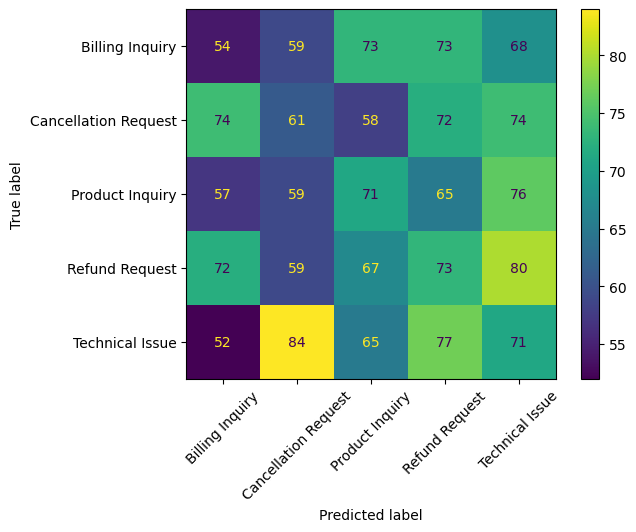

In [24]:
# Cell 11 — Visualize Confusion Matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=model.classes_
)

cm_display.plot(xticks_rotation=45)

In [25]:
# Cell 12 — Identify and Inspect Misclassified Tickets
comparison = pd.DataFrame({
    "Description": X_test.reset_index(drop=True),
    "Actual": y_test.reset_index(drop=True),
    "Predicted": y_pred
})

misclassified = comparison[
    comparison["Actual"] != comparison["Predicted"]
]

print(f"Total test tickets: {len(comparison)}")
print(f"Misclassified tickets: {len(misclassified)}")

misclassified.sample(
    min(10, len(misclassified)),
    random_state=42
)

Total test tickets: 1694
Misclassified tickets: 1364


,Description,Actual,Predicted
533,I'm having an issue with the {product_purchase...,Cancellation Request,Refund Request
1133,I'm having an issue with the {product_purchase...,Billing Inquiry,Cancellation Request
957,I'm having an issue with the {product_purchase...,Technical Issue,Cancellation Request
557,I'm having an issue with the {product_purchase...,Billing Inquiry,Product Inquiry
534,I'm having an issue with the {product_purchase...,Refund Request,Product Inquiry
1560,I'm having an issue with the {product_purchase...,Technical Issue,Cancellation Request
688,I'm having an issue with the {product_purchase...,Cancellation Request,Refund Request
471,I've forgotten my password for my {product_pur...,Cancellation Request,Billing Inquiry
765,I'm having an issue with the {product_purchase...,Billing Inquiry,Refund Request
1248,I'm having an issue with the {product_purchase...,Technical Issue,Product Inquiry


In [26]:
# Cell 13 — Analyze Errors by Ticket Type
errors_by_type = (
    misclassified
    .groupby(["Actual", "Predicted"])
    .size()
    .sort_values(ascending=False)
)

print(errors_by_type)

Actual                Predicted           
Technical Issue       Cancellation Request    84
Refund Request        Technical Issue         80
Technical Issue       Refund Request          77
Product Inquiry       Technical Issue         76
Cancellation Request  Technical Issue         74
                      Billing Inquiry         74
Billing Inquiry       Refund Request          73
                      Product Inquiry         73
Refund Request        Billing Inquiry         72
Cancellation Request  Refund Request          72
Billing Inquiry       Technical Issue         68
Refund Request        Product Inquiry         67
Product Inquiry       Refund Request          65
Technical Issue       Product Inquiry         65
Billing Inquiry       Cancellation Request    59
Product Inquiry       Cancellation Request    59
Refund Request        Cancellation Request    59
Cancellation Request  Product Inquiry         58
Product Inquiry       Billing Inquiry         57
Technical Issue       Bill

## Day 26 Conclusions

### Overall Model Performance

The Logistic Regression classifier achieved an overall accuracy of **19.48%** on the 1,694 tickets in the test set.

The weighted evaluation metrics were:

- **Precision:** 19.45%
- **Recall:** 19.48%
- **F1 Score:** 19.45%

The similar values across accuracy, precision, recall, and F1 indicate that the model did not perform strongly on any one of these overall measures.

### Performance by Ticket Type

The classification report showed low performance across all five Ticket Type classes.

- **Billing Inquiry:** F1 = 0.17
- **Cancellation Request:** F1 = 0.18
- **Product Inquiry:** F1 = 0.21
- **Refund Request:** F1 = 0.21
- **Technical Issue:** F1 = 0.20

No Ticket Type was classified with consistently high precision or recall.

### Error Analysis

Out of **1,694** test tickets, **1,364 were misclassified**, while 330 were classified correctly.

The most frequent specific confusion was:

**Technical Issue → Cancellation Request: 84 tickets**

Other frequent errors included:

- Refund Request → Technical Issue: 80
- Technical Issue → Refund Request: 77
- Product Inquiry → Technical Issue: 76
- Cancellation Request → Technical Issue: 74
- Cancellation Request → Billing Inquiry: 74

The confusion matrix therefore shows that errors are distributed across many combinations of Ticket Types rather than being isolated to only one category.

### Inspection of Ticket Descriptions

Inspection of misclassified examples showed that several descriptions contain generic or template-like language, such as:

> "I'm having an issue with the {product_purchased}..."

Descriptions like these may contain limited information that distinguishes one Ticket Type from another. This is a possible explanation for some classification errors and should be investigated further rather than assumed to be the only cause.

### Conclusion

The baseline TF-IDF + Logistic Regression pipeline successfully performs the complete classification process, but its measured predictive performance is low on this dataset.

The evaluation suggests that the next step should not simply be to assume that Logistic Regression is unsuitable. The ticket descriptions and their relationship to the Ticket Type labels should first be investigated to determine whether the input text contains enough distinguishing information for the target classes.

This baseline now provides measurable results that can be used for comparison with later approaches.